In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import jlinops

from solvers import MMGKS

# Toy problem

In [2]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.1
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=10, mode="reflect")
noisy_signal = A.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

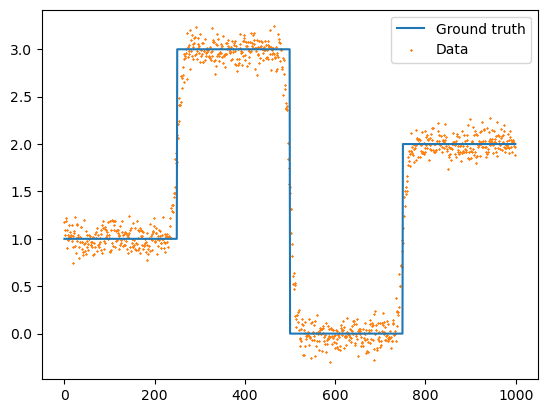

In [3]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization matrix

In [4]:
Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

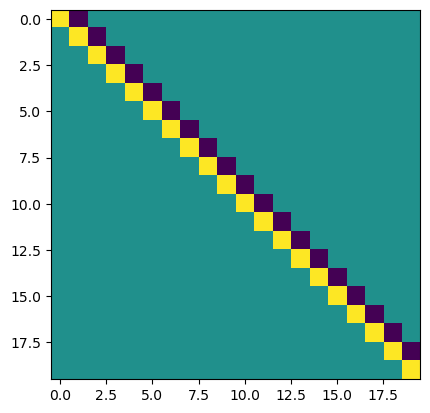

In [5]:
plt.imshow(Lmat.toarray()[:20,:20])
plt.show()

# Use solver

In [12]:
mmgks_solver = MMGKS(A, L, noisy_signal, noise_var=noise_var)
data = mmgks_solver.solve(n_iter=50, epsilon=1e-2, q=1.0, x_true=ground_truth, regparam="dp")

0.07071715488766377
0.045284521059775755
0.04706799491673026
0.04891133459524827
0.050815378397460975
0.05278086038318043
0.05480840114791316
0.05689849844627842
0.059051517697232006
0.06126768241594972
0.06354706462709071
0.06588957532531582
0.06829495506117486
0.07076276474351055
0.07329237676299538
0.07588296655487367
0.07853350473192663
0.081242749930555
0.08400924252309061
0.08683129935738573
0.08970700968979137
0.09263423247922861
0.09561059520765577
0.09863349438539373
0.10170009788813525
0.1048073492558419
0.10795197406204773
0.11113048843548809
0.11433920978475101
0.11757426974132903
0.12083162929773475
0.12410709607612438
0.12739634362020671
0.13069493256028233
0.13399833345934328
0.13730195110857848
0.1406011500046929
0.14389128071039078
0.14716770677432545
0.15042583186869674
0.1536611267922351
0.15686915598394818
0.1600456031989581
0.16318629601183227
0.16628722883466002
0.16934458416597337
0.17235475182164378
0.1753143459388547
0.178220219587979
0.18106947687327396
0.1838

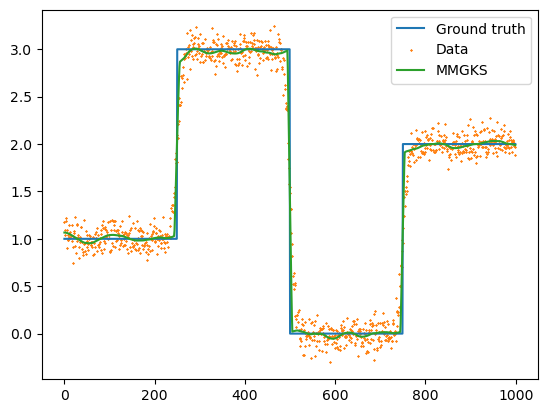

In [13]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.plot(grid, data["x"], label="MMGKS", color="C2")
plt.legend()
plt.show()
plt.show()

In [14]:
data["rre_history"][-1]

0.0662831691580489

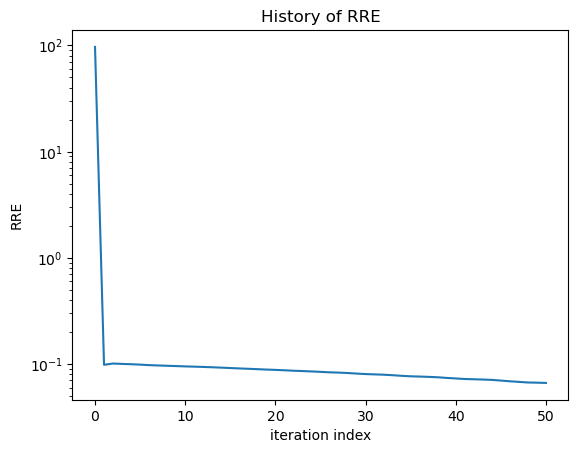

In [15]:
plt.plot(data["rre_history"])
plt.yscale("log")
plt.title("History of RRE")
plt.ylabel("RRE")
plt.xlabel("iteration index")
plt.show()

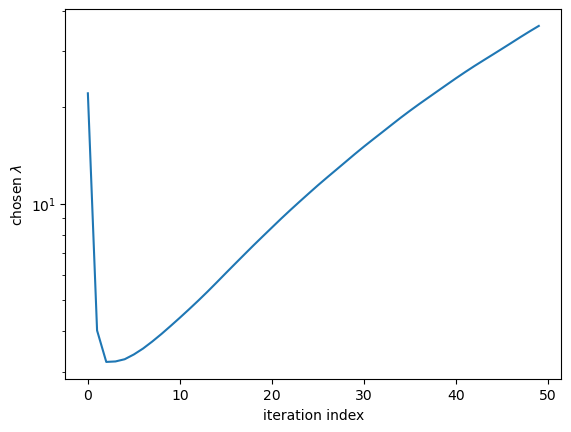

In [16]:
plt.plot(data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

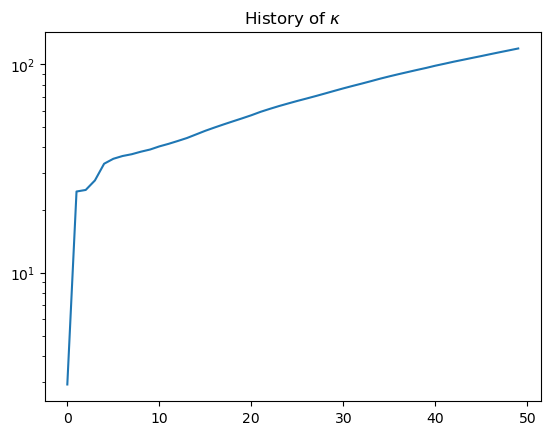

In [17]:
plt.plot(data["cond_ests"])
plt.yscale("log")
plt.title("History of $\\kappa$")
plt.show()